In [3]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

In [1]:
data_path = 'data/Performancetables_130242/2022-2023/'

na_all = ["", "NA", "SUPP", "NP", "NE", "SP", "SN", "LOWCOV", "NEW", "SUPPMAT"]

ks4 = pd.read_csv(data_path + "england_ks4final.csv",
                  na_values=na_all, dtype={"URN": str}, low_memory=False)
ks4 = ks4[ks4["URN"].notna()]
ks4 = ks4[["URN", "ATT8SCR", "P8MEA", "TOTPUPS", "TPUP", "PTFSM6CLA1A", "PTPRIORLO"]]
for c in ks4.columns.drop("URN"):
    ks4[c] = pd.to_numeric(ks4[c].astype(str).str.replace("%", "", regex=False),
                           errors="coerce")

absence = pd.read_csv(data_path + "england_abs.csv",
                      na_values=na_all, dtype={"URN": str}, low_memory=False)
absence = absence[absence["URN"].notna()].drop_duplicates("URN")
absence = absence[["URN", "PERCTOT"]]
absence["PERCTOT"] = pd.to_numeric(absence["PERCTOT"], errors="coerce")

school_info = pd.read_csv(data_path + "england_school_information.csv",
                          na_values=na_all, dtype={"URN": str}, low_memory=False)
school_info = school_info[["URN", "SCHNAME", "LANAME", "MINORGROUP",
                           "OFSTEDRATING", "ADMPOL", "RELCHAR", "GENDER"]]

schools = ks4.merge(school_info, on="URN", how="left") \
             .merge(absence, on="URN", how="left")

NameError: name 'pd' is not defined

In [7]:
len(schools)
print(schools.shape)
schools.info()

(5657, 15)
<class 'pandas.DataFrame'>
RangeIndex: 5657 entries, 0 to 5656
Data columns (total 15 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   URN           5657 non-null   str    
 1   ATT8SCR       4631 non-null   float64
 2   P8MEA         3616 non-null   float64
 3   TOTPUPS       5586 non-null   float64
 4   TPUP          5533 non-null   float64
 5   PTFSM6CLA1A   3979 non-null   float64
 6   PTPRIORLO     3979 non-null   float64
 7   SCHNAME       5657 non-null   str    
 8   LANAME        5657 non-null   str    
 9   MINORGROUP    5657 non-null   str    
 10  OFSTEDRATING  4816 non-null   str    
 11  ADMPOL        5211 non-null   str    
 12  RELCHAR       3215 non-null   str    
 13  GENDER        5657 non-null   str    
 14  PERCTOT       4154 non-null   float64
dtypes: float64(7), str(8)
memory usage: 1.1 MB


In [31]:
## Number of unique schools
print('Number of unique schools: ', nrow(schools))

## Number of schools with attainment 8 scores
print('Number of schools with attainment 8 scores: ', sum(!is.na(schools$ATT8SCR)))

SyntaxError: invalid syntax (1834998475.py, line 5)

In [27]:
# As it arrives: just text
sorted(schools["OFSTEDRATING"].dropna().unique())

['Good',
 'Inadequate',
 'Outstanding',
 'Requires improvement',
 'Serious Weaknesses',
 'Special Measures']

In [28]:
rating_order = ["Special Measures", "Serious Weaknesses", "Inadequate",
                "Requires improvement", "Good", "Outstanding"]

before = schools["OFSTEDRATING"].isna().sum()

schools["OFSTEDRATING"] = pd.Categorical(schools["OFSTEDRATING"],
                                         categories=rating_order,
                                         ordered=True)

print({"missing_before": int(before),
       "missing_after": int(schools["OFSTEDRATING"].isna().sum())})

{'missing_before': 841, 'missing_after': 841}


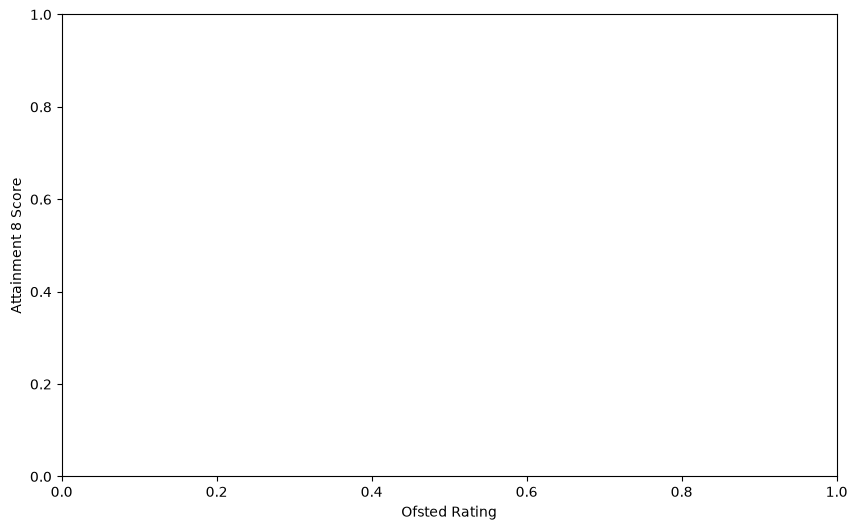

In [23]:
# Plot the distribution of attainment 8 scores by Ofsted rating before ordering 
plt.figure(figsize=(10, 6))
# plt.boxplot("??")
plt.xlabel("Ofsted Rating")
plt.ylabel("Attainment 8 Score")
plt.show()

Text(0, 0.5, 'Attainment 8 Score')

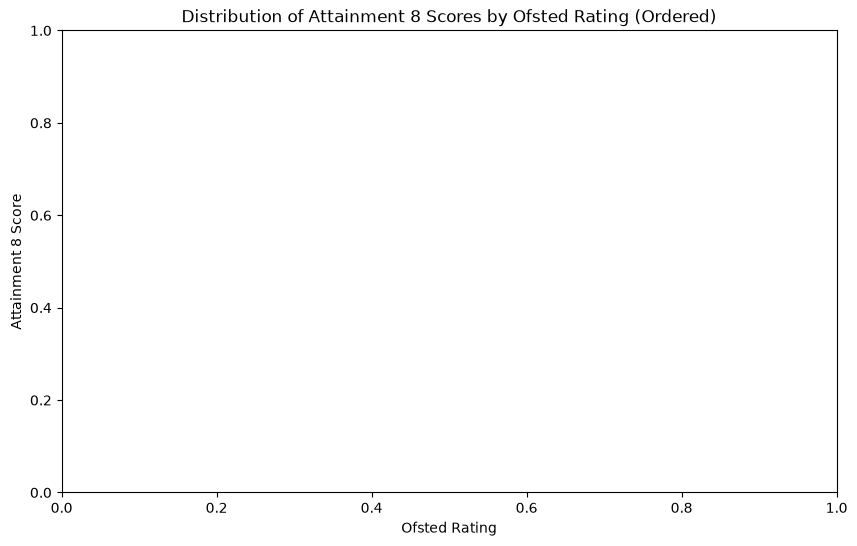

In [19]:
# Plot the distribution of attainment 8 scores by Ofsted rating after ordering 
plt.figure(figsize=(10, 6))
#sns.boxplot("??")
plt.title("Distribution of Attainment 8 Scores by Ofsted Rating (Ordered)")
plt.xlabel("Ofsted Rating")
plt.ylabel("Attainment 8 Score")

In [24]:
cols = ["ATT8SCR", "P8MEA", "PERCTOT", "PTFSM6CLA1A", "OFSTEDRATING"]
print((schools[cols].isna().mean() * 100).round(1))

tmp = schools[schools["TOTPUPS"].notna()].copy()
tmp["p8"] = np.where(tmp["P8MEA"].isna(),
                     "Progress 8 missing", "Progress 8 present")
print(tmp.groupby("p8")["TOTPUPS"].agg(schools="size", median_pupils="median"))

ATT8SCR         18.1
P8MEA           36.1
PERCTOT         26.6
PTFSM6CLA1A     29.7
OFSTEDRATING    14.9
dtype: float64
                    schools  median_pupils
p8                                        
Progress 8 missing     1981          126.0
Progress 8 present     3605         1019.0


In [25]:
schools["ATT8SCR"].describe()

count    4631.000000
mean       39.768063
std        17.529873
min         0.000000
25%        34.500000
50%        43.600000
75%        50.200000
max        87.600000
Name: ATT8SCR, dtype: float64